# Exercises XP: Time Series with LSTM

This is a guided notebook for the exercise on the platform. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear for important concepts.

## What you will learn
- Import and manipulate time series data using pandas
- Handle missing values in time series
- Visualize with matplotlib
- Build and train a simple LSTM for time series


## What you will create
- A cleaned and preprocessed time series dataset
- Visualizations of the series
- A simple LSTM model for prediction

## How I run this notebook
- Open it in Google Colab (File → Upload notebook).
- Run the cells top to bottom. The notebook downloads the course zip itself, so you do not need any local files.
- Random seeds are fixed (42) in the model cell, so results repeat.
- I ran the training on CPU with 5 epochs and hourly data so it finishes in a few minutes. On a Colab GPU you can use 15 epochs (as in the template) and try the finer minute-level resolution by commenting out the hourly resample.

# Part 1: Data Import and Initial Exploration

**Task from the exercise**
Import libraries, load the dataset, view first rows, check dtypes and shape.

**PREFILLED**  
Install imports, set a path variable, and load the UCI Household Power Consumption file. The file is usually semicolon separated with `?` as missing.

**What this cell does:** Downloads the course zip from GitHub and extracts `household_power_consumption.txt` into `./data`, so the PREFILLED loader can find it. This cell is my addition, because the template assumes the file is already there.

In [1]:
# Added setup cell: download the course zip and extract it into ./data
import urllib.request
import zipfile
from pathlib import Path

ZIP_URL = 'https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%206/W6D4/household_power_consumption.zip'
Path('./data').mkdir(exist_ok=True)
zip_path = Path('./data/household_power_consumption.zip')
if not Path('./data/household_power_consumption.txt').exists():
    urllib.request.urlretrieve(ZIP_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extract('household_power_consumption.txt', './data')
print('Ready:', Path('./data/household_power_consumption.txt').exists())

Ready: True


**What this cell does:** Imports the libraries, loads the minute-level household data into a DataFrame `df` indexed by time, and prints its shape and dtypes.

In [2]:
# PREFILLED: just execute
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', 100)

# Set this to your dataset path if different
DATA_PATH = Path('./data/household_power_consumption.txt')  # To-Do: change if needed

# Robust loader for semicolon separated file with ? as NA
parse_cols = {
    'Global_active_power': 'float64',
    'Global_reactive_power': 'float64',
    'Voltage': 'float64',
    'Global_intensity': 'float64',
    'Sub_metering_1': 'float64',
    'Sub_metering_2': 'float64',
    'Sub_metering_3': 'float64',
}
usecols = ['Date','Time'] + list(parse_cols.keys())

df = pd.read_csv(
    DATA_PATH,
    sep=';',
    na_values=['?'],
    usecols=usecols,
    dtype=parse_cols,
    parse_dates={'Datetime': ['Date','Time']},
    infer_datetime_format=True,
    dayfirst=True,
)

df = df.set_index('Datetime').sort_index()
print('Shape:', df.shape)
display(df.head())
display(df.dtypes)

/tmp/ipykernel_108561/3381433657.py:24: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  df = pd.read_csv(
/tmp/ipykernel_108561/3381433657.py:24: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv(


Shape: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

# Part 2: Handling Missing Values

**Task from the exercise**
Identify columns with missing values. Fill missing values using the mean of each column. Verify there are no missing values left.

**To-Do (code):** Compute a missing value summary, then fill numeric columns with their mean. Recheck for remaining NaNs.

**What this cell does:** Counts the missing values per column, fills each numeric column with its own mean, and checks that no NaNs are left.

In [3]:
# Missing values per column before filling
missing_before = df.isna().sum().sort_values(ascending=False)
print('Missing before:'); display(missing_before[missing_before > 0])

# Fill every numeric column with that column's mean
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

# Verify: there should be no NaNs left
missing_after = df.isna().sum().sum()
print('Total missing after fill:', int(missing_after))
assert missing_after == 0

Missing before:


Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Total missing after fill: 0


# Part 3: Data Visualization

**Task from the exercise**
Resample the `Global_active_power` column over a day and plot the sum and mean. Plot the mean and standard deviation of `Global_intensity` resampled over a day.

**PREFILLED**  
Helper plotting functions using matplotlib.

**What this cell does:** Defines the two plotting helpers (PREFILLED). Each one resamples a series to daily values and plots them. Nothing is drawn until they are called.

In [4]:
# PREFILLED: just execute
def plot_daily_sum_and_mean(series, title_prefix='Global_active_power'):
    daily = series.resample('1D')
    s = daily.sum(min_count=1)
    m = daily.mean()
    plt.figure(figsize=(8,3))
    plt.plot(s.index, s.values)
    plt.title(f'{title_prefix} daily sum')
    plt.xlabel('date'); plt.ylabel('sum'); plt.tight_layout(); plt.show()
    plt.figure(figsize=(8,3))
    plt.plot(m.index, m.values)
    plt.title(f'{title_prefix} daily mean')
    plt.xlabel('date'); plt.ylabel('mean'); plt.tight_layout(); plt.show()

def plot_daily_mean_std(series, title_prefix='Global_intensity'):
    daily = series.resample('1D')
    m = daily.mean()
    sd = daily.std()
    plt.figure(figsize=(8,3))
    plt.plot(m.index, m.values, label='mean')
    plt.plot(sd.index, sd.values, label='std')
    plt.title(f'{title_prefix} daily mean and std')
    plt.xlabel('date'); plt.ylabel('value')
    plt.legend(); plt.tight_layout(); plt.show()

**To-Do (code):** Call the helpers on the required columns. If a plot seems too dense, slice a recent time window.

**What this cell does:** Calls both helpers on the original minute-level columns. The helpers do the daily resampling inside, so `df` is still minute-level at this point.

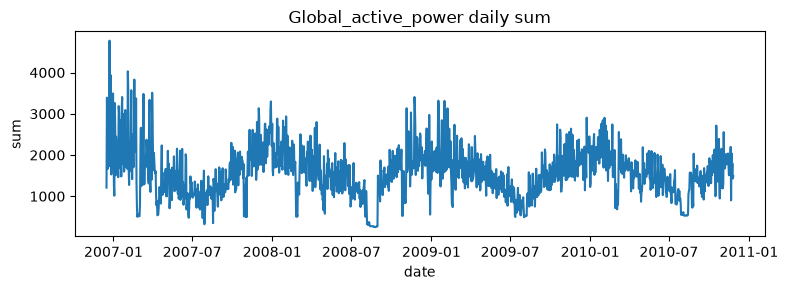

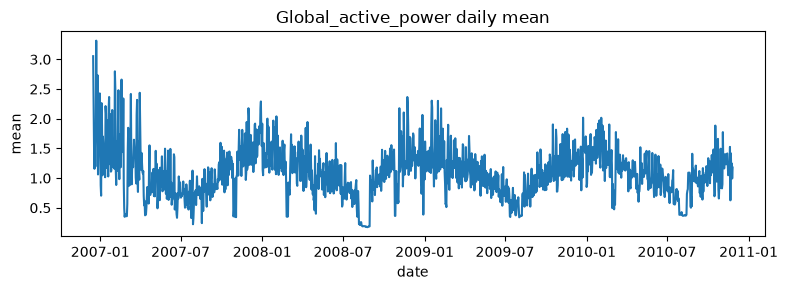

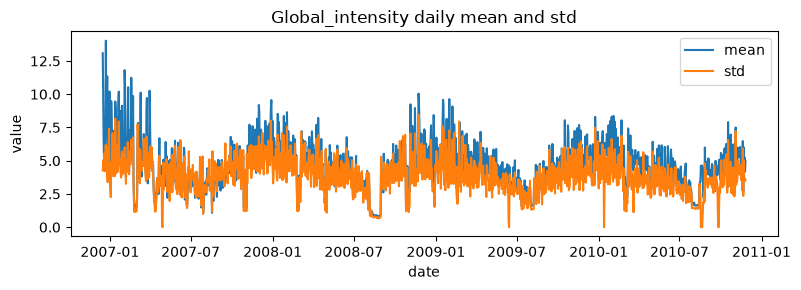

In [5]:
# Daily sum and mean of Global_active_power
plot_daily_sum_and_mean(df['Global_active_power'], title_prefix='Global_active_power')
# Daily mean and std of Global_intensity
plot_daily_mean_std(df['Global_intensity'], title_prefix='Global_intensity')

# Part 4: Data Preprocessing for LSTM

**Task from the exercise**
Normalize the dataset, split into train and test, and reshape for LSTM input.

**Learning point**  
LSTMs consume sequences with shape [batch, time, features]. You must build sliding windows. Use a lookback window and predict the next step.

![image.png](https://github.com/user-attachments/assets/be3e815f-2aff-4e8d-ac48-eca27b1c729c)

**PREFILLED**  
Windowing helpers and a train test split by time.

**Added step: resample to hourly (not in the template)**

The raw file has about 2.07 million minute-level rows. The windowing cell below turns every row into a 48-step window of 7 features. For the training windows alone that needs several GB of memory, and it is too slow on CPU. So I average the minutes into hourly rows first, which gives about 34,600 rows. Each window is now 48 hours, not 48 minutes. The Part 3 plots above used the minute data, as the exercise asks. Only the model input is hourly from here on.

**What this cell does:** Replaces `df` with the hourly mean of every column. Hours with no minute rows at all (421 in this file) become NaN, so I fill them with column means, the same rule as Part 2. To try a finer resolution on a Colab GPU, comment out both lines of code.

In [6]:
# Resample the minute-level data to hourly means
df = df.resample('1h').mean()
# Hours with no minute rows at all are NaN now; fill them with column means
df = df.fillna(df.mean())
print('Hourly shape:', df.shape, '| NaNs left:', int(df.isna().sum().sum()))

Hourly shape: (34589, 7) | NaNs left: 0


**What this cell does:** Keeps the 7 feature columns, scales them to 0 to 1, splits them 80/20 by time, and builds 48-step windows. Each window predicts the next hour's `Global_active_power`.

In [7]:
# PREFILLED: just execute
from sklearn.preprocessing import MinMaxScaler

def make_windows(arr_2d, window=48, horizon=1):
    X, y = [], []
    for i in range(len(arr_2d) - window - horizon + 1):
        X.append(arr_2d[i:i+window])
        y.append(arr_2d[i+window:i+window+horizon, 0])
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    return X, y

def time_train_test_split(df, split_ratio=0.8):
    n = len(df)
    k = int(n * split_ratio)
    return df.iloc[:k].copy(), df.iloc[k:].copy()

feat_cols = ['Global_active_power','Global_reactive_power','Voltage','Global_intensity',
             'Sub_metering_1','Sub_metering_2','Sub_metering_3']
df_feats = df[feat_cols].copy()

df_tr, df_te = time_train_test_split(df_feats, split_ratio=0.8)

scaler = MinMaxScaler()
tr_scaled = scaler.fit_transform(df_tr.values)
te_scaled = scaler.transform(df_te.values)

WINDOW = 48
HORIZON = 1
X_tr, y_tr = make_windows(tr_scaled, window=WINDOW, horizon=HORIZON)
X_te, y_te = make_windows(te_scaled, window=WINDOW, horizon=HORIZON)

print('Train windows:', X_tr.shape, 'Train targets:', X_tr.shape)
print('Test windows:', X_te.shape, 'Test targets:', X_te.shape)

Train windows: (27623, 48, 7) Train targets: (27623, 48, 7)
Test windows: (6870, 48, 7) Test targets: (6870, 48, 7)


> **To-Do (write here):** State which column you predict as the target and why. If you changed `feat_cols`, note your choice.

**My answer:** I predict `Global_active_power` (column 0 in the window helper). I chose it because it is the household's total active power, so it is the main consumption signal. I kept the template `feat_cols` unchanged, so all 7 columns are still inputs to the model.

# Part 5: Building an LSTM Model

**Task from the exercise**
Import the libraries, define the LSTM architecture, and compile with a suitable loss and optimizer.

**To-Do (code):** Build a small LSTM with one or two LSTM layers and a Dense output of size `HORIZON`. Use `mse` loss and `adam` optimizer. Print `model.summary()`.

**What this cell does:** Builds the LSTM: one LSTM layer with 64 units, then a Dense layer that outputs `HORIZON` values. It compiles with Adam, MSE loss and MAE as a metric, and prints the model summary.

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Fix the random seeds so the run is repeatable
np.random.seed(42)
tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(WINDOW, X_tr.shape[-1])),  # (48 hours, 7 features)
    layers.LSTM(64, return_sequences=False),       # reads the window, keeps the last state
    layers.Dense(HORIZON),                         # predicts the next hour
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,497 (72.25 KB)

 Trainable params: 18,497 (72.25 KB)

 Non-trainable params: 0 (0.00 B)

# Part 6: Training and Evaluating the LSTM Model

**Task from the exercise**
Train the model, evaluate on the test set, and plot training and validation loss.

**PREFILLED**  
Callbacks and plotting helper. You supply the model and data in the To-Do cell.

**What this cell does:** Defines the training helper (PREFILLED). It trains with early stopping and learning-rate reduction, then plots the training and validation loss.

In [9]:
# PREFILLED: just execute
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def fit_and_plot(model, X_tr, y_tr, X_te, y_te, epochs=10, batch=256):
    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)
    h = model.fit(X_tr, y_tr, validation_data=(X_te, y_te),
                  epochs=epochs, batch_size=batch, callbacks=[es, rl], verbose=2)
    plt.figure(figsize=(6,4))
    plt.plot(h.history['loss'], label='loss')
    plt.plot(h.history['val_loss'], label='val_loss')
    plt.title('Training and validation loss')
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.tight_layout(); plt.show()
    return h

**To-Do (code):** Train and evaluate. Report final test MAE and MSE.

**What this cell does:** Trains the model for 5 epochs, evaluates it on the test windows, and prints the test MSE and MAE. I use 5 epochs to keep the CPU run short; the template uses 15 on a GPU.

Epoch 1/5


108/108 - 4s - 34ms/step - loss: 0.0137 - mae: 0.0881 - val_loss: 0.0074 - val_mae: 0.0640 - learning_rate: 0.0010


Epoch 2/5


108/108 - 2s - 22ms/step - loss: 0.0102 - mae: 0.0731 - val_loss: 0.0067 - val_mae: 0.0583 - learning_rate: 0.0010


Epoch 3/5


108/108 - 2s - 22ms/step - loss: 0.0092 - mae: 0.0692 - val_loss: 0.0064 - val_mae: 0.0576 - learning_rate: 0.0010


Epoch 4/5


108/108 - 2s - 22ms/step - loss: 0.0087 - mae: 0.0671 - val_loss: 0.0062 - val_mae: 0.0570 - learning_rate: 0.0010


Epoch 5/5


108/108 - 2s - 23ms/step - loss: 0.0084 - mae: 0.0655 - val_loss: 0.0060 - val_mae: 0.0557 - learning_rate: 0.0010


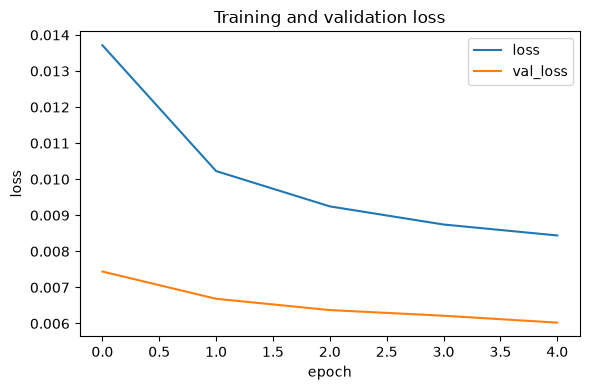

Test MSE: 0.006023
Test MAE: 0.055679


In [10]:
# 5 epochs keeps the CPU run short.
# On Colab GPU you can use epochs=15, as in the template.
hist = fit_and_plot(model, X_tr, y_tr, X_te, y_te, epochs=5, batch=256)

# evaluate() returns the loss (MSE) and the MAE metric, in that order
eval_mse, eval_mae = model.evaluate(X_te, y_te, verbose=0)
print('Test MSE:', round(float(eval_mse), 6))
print('Test MAE:', round(float(eval_mae), 6))